# ELEC70143 In-Class Exercise — Air Pollution Monitoring (CO prediction)

Target: `CO(GT)` (mg/m³). Data: `q1.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, RidgeCV, LassoCV
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
TARGET = "CO(GT)"

In [2]:
df = pd.read_csv("data/q1.csv")
FEATURES = [c for c in df.columns if c != TARGET]

SENSOR_COST = {
    "PT08.S1(CO)": 1000,
    "PT08.S2(NMHC)": 800,
    "PT08.S3(NOx)": 700,
    "PT08.S4(NO2)": 700,
    "PT08.S5(O3)": 900,
    "T": 150,
    "RH": 150,
    "AH": 200,
    "NOx(GT)": 1800,
    "NO2(GT)": 1800,
    "C6H6(GT)": 2500,
}

df.head()

,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,2.6,1360.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,2.0,1292.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,2.2,1402.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,2.2,1376.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,1.6,1272.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


## A. Missing data

- Report % missing per feature
- Propose and justify a strategy, then implement it

,missing %
NO2(GT),5.42
NOx(GT),5.38
PT08.S1(CO),4.30
C6H6(GT),4.30
PT08.S5(O3),4.30
PT08.S2(NMHC),4.30
PT08.S3(NOx),4.30
PT08.S4(NO2),4.30
RH,4.30
T,4.30


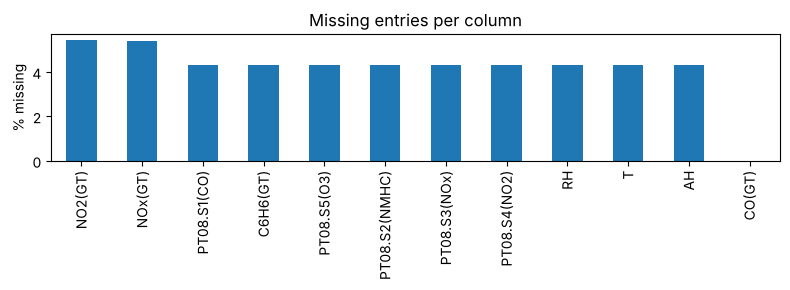

In [3]:
# A1. Percentage of missing entries per column
# A1. 每一列的缺失百分比
missing_pct = df.isna().mean() * 100
missing_tbl = missing_pct.round(2).sort_values(ascending=False).to_frame("missing %")
display(missing_tbl)

missing_pct.sort_values(ascending=False).plot.bar(figsize=(8, 3))
plt.ylabel("% missing")
plt.title("Missing entries per column")
plt.tight_layout()
plt.show()

In [4]:
# A2. Missingness pattern: which columns are missing together?
# A2. 缺失模式：哪些列是同时缺失的？
mask = df.isna()

pattern = mask.apply(lambda row: ", ".join(row[row].index) if row.any() else "(none)", axis=1)
pattern_counts = pattern.value_counts().to_frame("n_rows")
pattern_counts["% rows"] = (pattern_counts["n_rows"] / len(df) * 100).round(2)
display(pattern_counts)

# Number of missing values per row / 每一行缺了几个值
print("Number of missing values per row:")
display(mask.sum(axis=1).value_counts().sort_index())

,n_rows,% rows
(none),6941,90.45
"NOx(GT), NO2(GT)",400,5.21
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), PT08.S3(NOx), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",317,4.13
"PT08.S1(CO), C6H6(GT), PT08.S2(NMHC), NOx(GT), PT08.S3(NOx), NO2(GT), PT08.S4(NO2), PT08.S5(O3), T, RH, AH",13,0.17
NO2(GT),3,0.04


Number of missing values per row:


0     6941
1        3
2      400
9      317
11      13
Name: count, dtype: int64

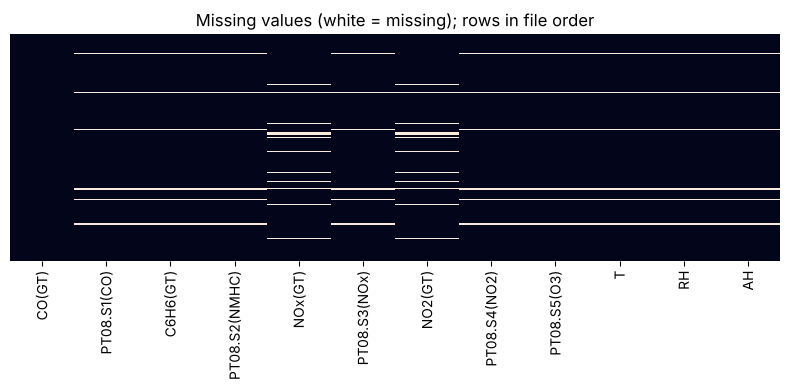

Device-offline rows: 330 in 13 contiguous blocks; longest block = 75 rows, median = 9 rows


In [5]:
# A3. Visualise missingness in row order and measure the "device-offline" blocks
# A3. 按行顺序可视化缺失，并统计"设备掉线"的连续缺失块
plt.figure(figsize=(8, 4))
sns.heatmap(mask, cbar=False, yticklabels=False)
plt.title("Missing values (white = missing); rows in file order")
plt.tight_layout()
plt.show()

# A row is "offline" when all 9 low-cost + meteorological sensors are missing
# 当 9 个低成本传感器和气象传感器全部缺失时，这一行视为"掉线"
offline = mask[FEATURES].sum(axis=1) >= 9
block_id = (offline != offline.shift()).cumsum()    # new id whenever the state changes / 状态变化时编号加一
block_len = block_id[offline].value_counts()
print(f"Device-offline rows: {offline.sum()} in {len(block_len)} contiguous blocks; "
      f"longest block = {block_len.max()} rows, median = {int(block_len.median())} rows")

In [6]:
# A4. Is missingness related to the target? Compare CO on offline vs other rows
# A4. 缺失是否和目标有关？比较掉线行和其他行的 CO
compare = pd.DataFrame({
    "offline rows": df.loc[offline, TARGET].describe(),
    "other rows": df.loc[~offline, TARGET].describe(),
})
compare.loc["P(CO>5)"] = [(df.loc[offline, TARGET] > 5).mean(), (df.loc[~offline, TARGET] > 5).mean()]
display(compare.round(3))

# How many exceedance events (CO > 5) would be lost by dropping offline rows?
# 如果删掉掉线行，会丢掉多少个超标事件（CO > 5）？
n_exceed_total = (df[TARGET] > 5).sum()
n_exceed_offline = (df.loc[offline, TARGET] > 5).sum()
print(f"Exceedances on offline rows: {n_exceed_offline} of {n_exceed_total} "
      f"({n_exceed_offline / n_exceed_total * 100:.1f}%)")

,offline rows,other rows
count,330.000,7344.000
mean,2.665,2.130
std,1.710,1.436
min,0.300,0.100
25%,1.500,1.100
50%,2.200,1.800
75%,3.500,2.800
max,9.300,11.900
P(CO>5),0.100,0.042


Exceedances on offline rows: 33 of 344 (9.6%)


In [7]:
# A5. Sanity checks on the raw data
# A5. 原始数据的合理性检查

# (a) The original UCI file uses -200 as a missing-value code; check none are left
# (a) 原始 UCI 数据用 -200 表示缺失，检查这里是否还有残留
print("Any -200 sentinel values:", (df == -200).any().any())
print("Column minima:")
display(df.min().round(2).to_frame("min").T)

# (b) Are consecutive rows consecutive hours? Large hour-to-hour temperature jumps suggest not
# (b) 相邻两行是否是相邻的小时？如果温度经常大幅跳变，说明中间有被删掉的行
t_jump = df["T"].diff().abs()
print(f"Rows: {len(df)} (original UCI dataset has 9357 hourly rows)")
print(f"Hour-to-hour temperature jumps > 5 °C: {(t_jump > 5).sum()}")

Any -200 sentinel values: False
Column minima:


,CO(GT),PT08.S1(CO),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
min,0.1,647.0,0.2,387.0,2.0,322.0,2.0,551.0,221.0,-1.9,9.2,0.18


Rows: 7674 (original UCI dataset has 9357 hourly rows)
Hour-to-hour temperature jumps > 5 °C: 47


In [8]:
# A6. Strategy step 1: drop the device-offline rows
# A6. 处理策略第 1 步：删掉设备掉线的行
df_clean = df.loc[~offline].reset_index(drop=True)
print(f"Dropped {offline.sum()} rows ({offline.mean()*100:.2f}%); remaining = {len(df_clean)}")

# Only the reference analysers NOx(GT) / NO2(GT) still have gaps
# 剩下的缺失只有参考仪器 NOx(GT) / NO2(GT)
display((df_clean.isna().mean() * 100).round(2)[lambda s: s > 0])

Dropped 330 rows (4.30%); remaining = 7344


NOx(GT)    5.45
NO2(GT)    5.49
dtype: float64

In [9]:
# A7. Strategy step 2: KNN imputation for the remaining gaps
# A7. 处理策略第 2 步：用 KNN 填补剩余的缺失
from sklearn.impute import KNNImputer

def knn_impute(fit_df, *other_dfs, cols=FEATURES, k=5):
    """Fit scaler + KNNImputer on fit_df[cols] only, then impute fit_df and any other_dfs.
    只在 fit_df 上拟合标准化器和 KNN 插补器，然后对 fit_df 和 other_dfs 做插补。

    Scaling first because KNN uses Euclidean distance.
    先标准化，因为 KNN 用欧氏距离，否则数值大的列会主导距离。
    The target is NOT used, since it would not be available at prediction time.
    不使用目标 CO，因为预测时拿不到它。
    """
    scaler = StandardScaler().fit(fit_df[cols])              # NaNs are ignored when fitting / 拟合时自动忽略 NaN
    imputer = KNNImputer(n_neighbors=k).fit(scaler.transform(fit_df[cols]))

    out = []
    for d in (fit_df,) + other_dfs:
        d = d.copy()
        filled = imputer.transform(scaler.transform(d[cols]))
        d[cols] = scaler.inverse_transform(filled)           # back to original units / 变回原始单位
        out.append(d)
    return out[0] if len(out) == 1 else out

# For EDA (Part B) we impute on the full cleaned data.
# 探索性分析（B 题）用全部清洗后的数据做插补。
# Modelling (Part C onwards) uses the train-only version in A9 below.
# 建模（C 题起）用下面 A9 里只在训练集上拟合的版本。
df_imp = knn_impute(df_clean)
print("Remaining NaNs after imputation:", df_imp.isna().sum().sum())

Remaining NaNs after imputation: 0


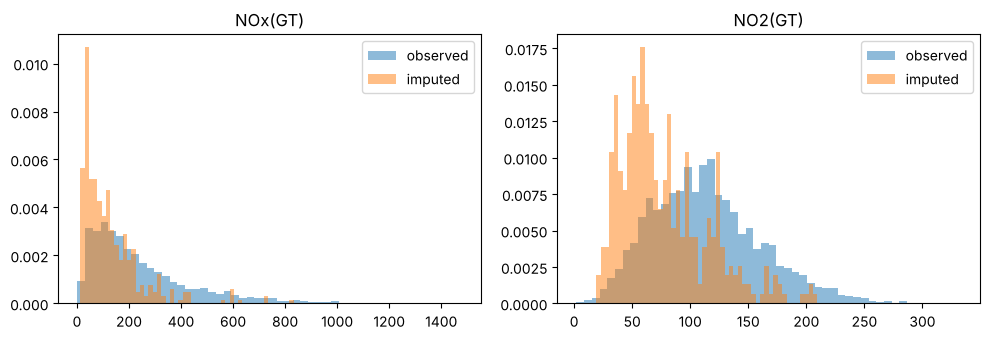

,before (observed),after (all rows)
NOx(GT),250.6,243.9
NO2(GT),113.9,111.9


In [10]:
# A8. Check that imputed values look like the observed ones
# A8. 检查插补值的分布是否和观测值相似
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, ["NOx(GT)", "NO2(GT)"]):
    was_missing = df_clean[col].isna()
    ax.hist(df_clean[col].dropna(), bins=50, density=True, alpha=0.5, label="observed")
    ax.hist(df_imp.loc[was_missing, col], bins=50, density=True, alpha=0.5, label="imputed")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "before (observed)": df_clean[["NOx(GT)", "NO2(GT)"]].mean(),
    "after (all rows)": df_imp[["NOx(GT)", "NO2(GT)"]].mean(),
}).round(1))

### A9. Modelling data (used from Part C onwards)

80/20 random split **first**, then fit the imputer on the training set only, so no test-set information leaks into training.

先做 80/20 随机划分，再**只在训练集上**拟合插补器，避免测试集信息泄漏。

In [11]:
# A9. Train/test split, then train-only imputation
# A9. 先划分训练集 / 测试集，再只用训练集拟合插补器
train_df, test_df = train_test_split(df_clean, test_size=0.2, random_state=RANDOM_STATE)
train_imp, test_imp = knn_impute(train_df, test_df)

X_train, y_train = train_imp[FEATURES], train_imp[TARGET]
X_test, y_test = test_imp[FEATURES], test_imp[TARGET]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("NaNs left (train, test):", X_train.isna().sum().sum(), X_test.isna().sum().sum())

Train: (5875, 11)  Test: (1469, 11)
NaNs left (train, test): 0 0


**Discussion (A):**

**Missing entries.** The target `CO(GT)` is complete. The nine low-cost and meteorological sensors (PT08.S1–S5, T, RH, AH) and `C6H6(GT)` each have **4.30%** missing; the reference analysers `NOx(GT)` and `NO2(GT)` have **5.38%** and **5.42%**. No `-200` sentinel codes remain.

**Pattern.** Missingness is **block-wise**, not scattered:
- 330 rows (4.30%) are **device-offline**: all nine sensors are missing at once, in 13 contiguous blocks of up to 75 rows.
- 400 rows (5.2%) miss only the NOx/NO2 reference pair, and 3 rows miss only NO2(GT).

**Strategy: drop offline rows + KNN imputation (k = 5, on standardised features), fitted on the training set only.**
1. *Why drop the offline rows?*
   - In those rows only NOx/NO2 remain, so any imputation of the other nine columns is close to guessing. In our masking experiment (`imputation_comparison.ipynb`, Exp. 2) KNN and MICE reached a normalised MAE of 0.6–0.75, barely better than median (≈0.8).
   - Time interpolation is unreliable here. The file has 7,674 rows versus 9,357 in the original hourly dataset, consistent with rows lacking `CO(GT)` having been removed, so consecutive rows are not necessarily consecutive hours (we also see 47 hour-to-hour temperature jumps > 5 °C).
   - Operationally, a deployed monitor cannot predict when its sensors are offline anyway.
   - In Exp. 3, dropping these rows gave the joint-best CV RMSE (0.4334, versus 0.4336 for KNN on all rows and 0.4449 for median).
2. *Why KNN for the rest?* Once offline rows are removed, every gap has nine observed, strongly correlated sensors (see B) to find neighbours from.
   - In Exp. 1 KNN had the lowest error for NOx/NO2: normalised MAE 0.198, versus 0.740 for median.
   - Mean or median imputation would shrink variance and weaken the correlations the regression relies on.
   - The imputed values have a distribution similar to the observed ones (A8).
3. *Leakage.* The imputer is fitted on the training split only (A9). The target is never used for imputation.

**Caveat: the data are not missing completely at random (not MCAR).** CO is higher when the device is offline (mean 2.67 vs 2.13 mg/m³; P(CO > 5) = 10.0% vs 4.2%). Dropping these rows removes 33 of 344 exceedance events (9.6%). This slightly understates how often dangerous events occur, which matters for the alert-cost analysis in G and H.

> **中文要点：** 目标没有缺失；特征缺失 4.3% 到 5.4%，而且是成块出现的（设备整体掉线）。处理方法是删掉 330 行掉线数据，剩下的 NOx/NO2 缺失用 KNN 填补，只在训练集上拟合。理由：掉线行只剩 2 个特征，插补近乎瞎猜；行与行之间不一定是连续的小时，时间插值不可靠；实验 3 中删行的效果并列最好。注意：掉线时 CO 偏高，删行会少掉约 10% 的超标事件。

## B. Distributions & correlations

- Correlation plot / pairs plot of main features + target
- Comment on strong correlations and multicollinearity

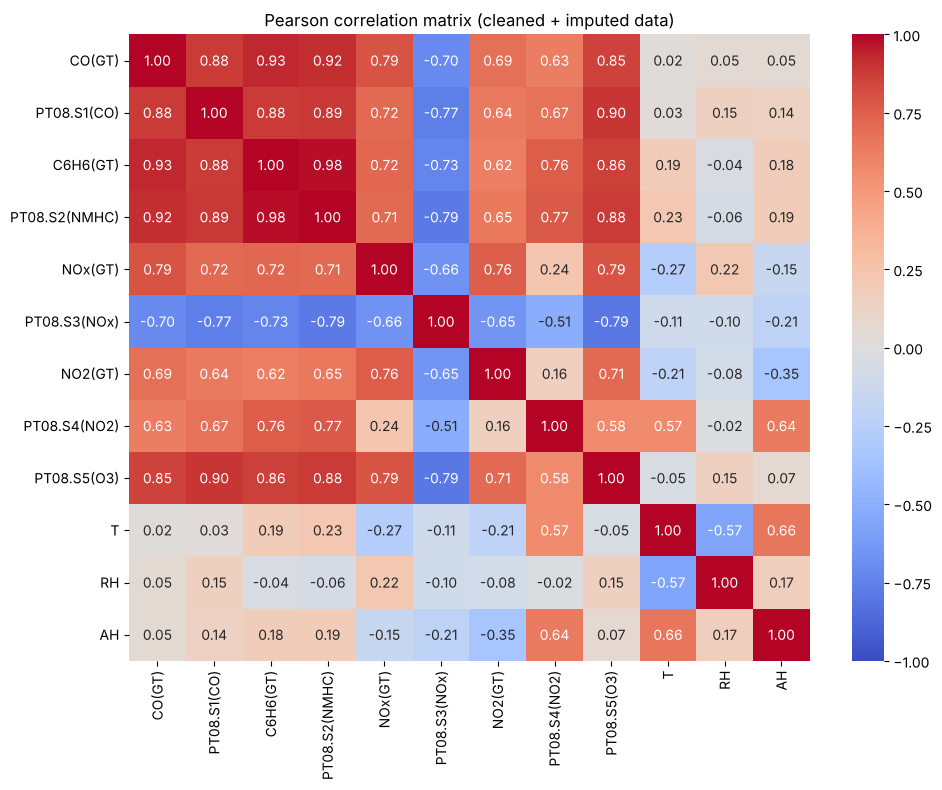

In [12]:
# B1. Correlation heatmap of all features and the target
# B1. 所有特征和目标的相关系数热力图
corr = df_imp.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Pearson correlation matrix (cleaned + imputed data)")
plt.tight_layout()
plt.show()

In [13]:
# B2. Correlation of each feature with the target, sorted
# B2. 每个特征和目标的相关系数，按大小排序
display(corr[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_frame("r with CO(GT)"))

# Most correlated feature pairs (excluding the target)
# 特征之间相关性最强的几对（不含目标）
feat_corr = corr.loc[FEATURES, FEATURES]
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))   # upper triangle only / 只取上三角，避免重复
         .stack().rename("r").to_frame())
pairs["|r|"] = pairs["r"].abs()
display(pairs.sort_values("|r|", ascending=False).head(10).round(3))

,r with CO(GT)
C6H6(GT),0.931
PT08.S2(NMHC),0.916
PT08.S1(CO),0.879
PT08.S5(O3),0.854
NOx(GT),0.791
NO2(GT),0.686
PT08.S4(NO2),0.631
RH,0.049
AH,0.049
T,0.022


r    |r|
C6H6(GT)      PT08.S2(NMHC)  0.982  0.982
PT08.S1(CO)   PT08.S5(O3)    0.898  0.898
              PT08.S2(NMHC)  0.888  0.888
              C6H6(GT)       0.879  0.879
PT08.S2(NMHC) PT08.S5(O3)    0.877  0.877
C6H6(GT)      PT08.S5(O3)    0.862  0.862
PT08.S3(NOx)  PT08.S5(O3)   -0.794  0.794
NOx(GT)       PT08.S5(O3)    0.792  0.792
PT08.S2(NMHC) PT08.S3(NOx)  -0.785  0.785
              PT08.S4(NO2)   0.772  0.772

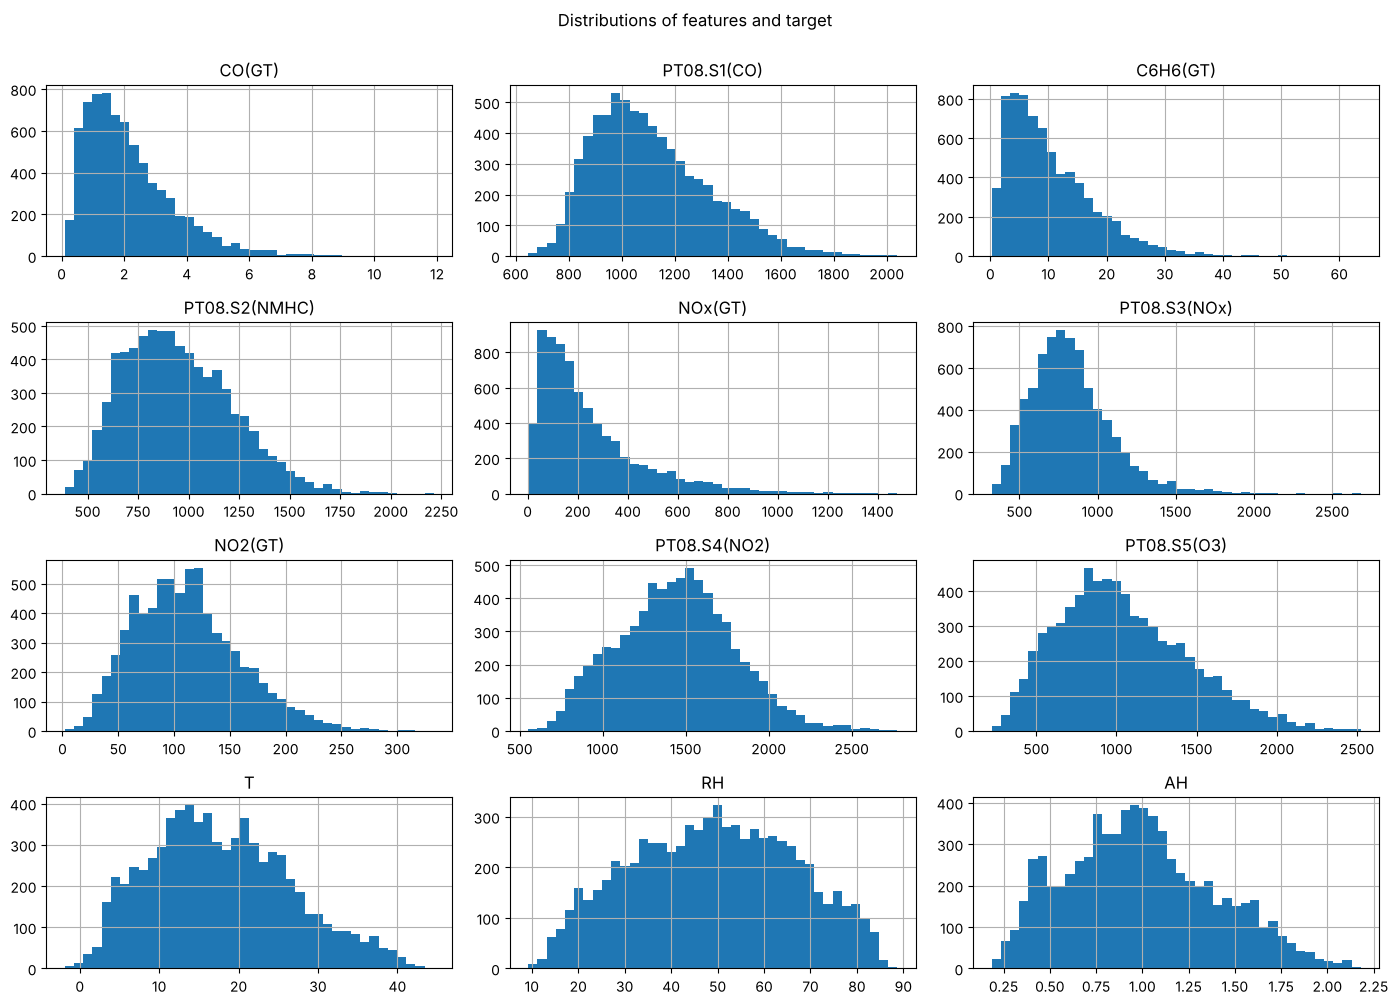

,skewness
NOx(GT),1.68
CO(GT),1.36
C6H6(GT),1.33
PT08.S3(NOx),1.15
PT08.S1(CO),0.73
NO2(GT),0.59
PT08.S5(O3),0.58
PT08.S2(NMHC),0.53
T,0.38
AH,0.34


In [14]:
# B3. Distributions: histograms and skewness
# B3. 分布：直方图和偏度
df_imp.hist(bins=40, figsize=(14, 10))
plt.suptitle("Distributions of features and target", y=1.0)
plt.tight_layout()
plt.show()

# Skewness > 1 means strongly right-skewed (long right tail)
# 偏度 > 1 表示明显右偏（右侧有长尾）
display(df_imp.skew().sort_values(ascending=False).round(2).to_frame("skewness"))

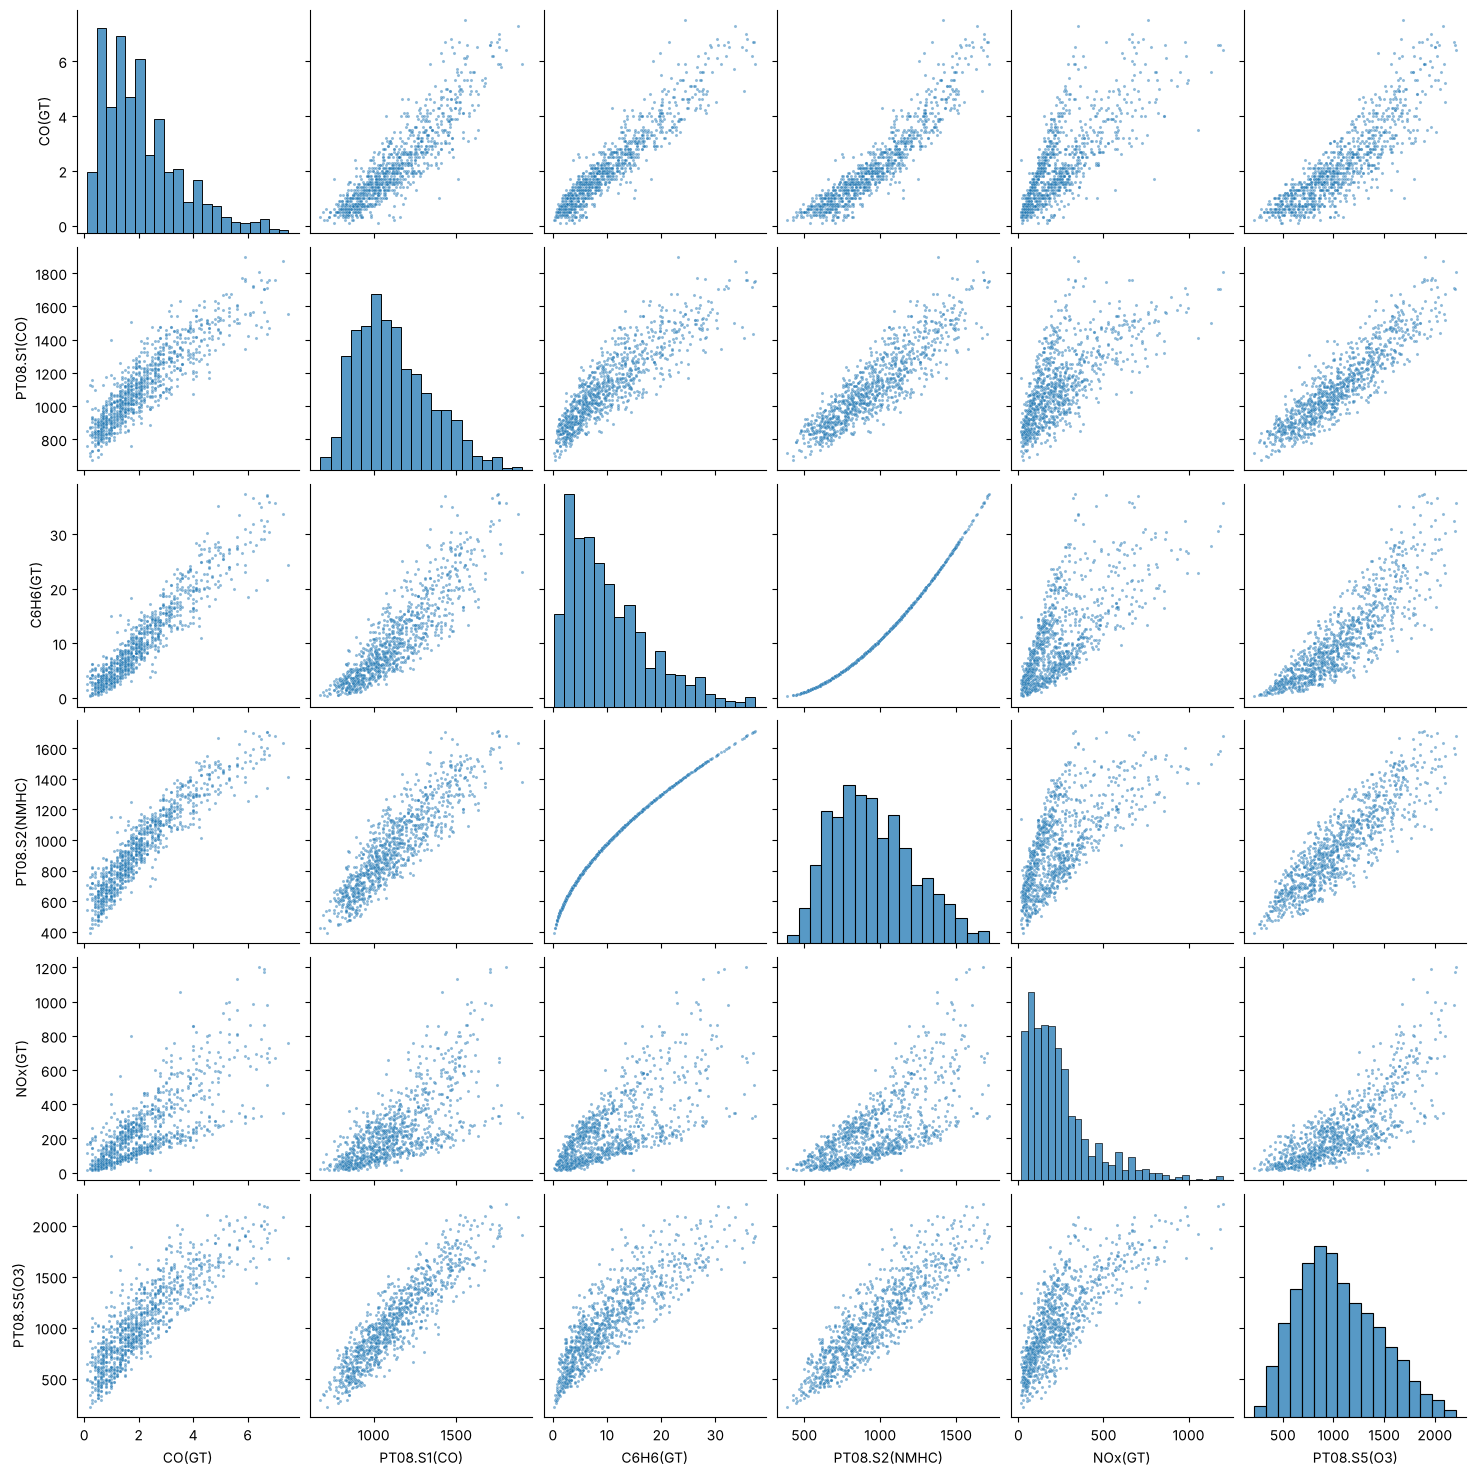

In [15]:
# B4. Pairs plot of the target and the most correlated features
# B4. 目标和相关性最强的几个特征的两两散点图
main_vars = [TARGET, "PT08.S1(CO)", "C6H6(GT)", "PT08.S2(NMHC)", "NOx(GT)", "PT08.S5(O3)"]

# Sample 1000 rows so the plot is readable and fast
# 抽样 1000 行，让图更清楚、画得更快
sns.pairplot(df_imp[main_vars].sample(1000, random_state=RANDOM_STATE),
             plot_kws={"s": 5, "alpha": 0.5})
plt.show()

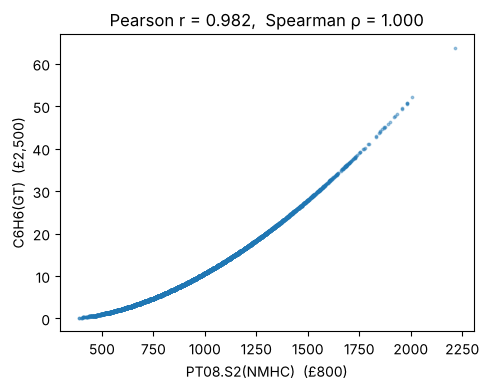

In [16]:
# B5. Closer look: C6H6(GT) is almost a deterministic function of PT08.S2(NMHC)
# B5. 细看：C6H6(GT) 几乎是 PT08.S2(NMHC) 的确定性函数
pear = df_imp["C6H6(GT)"].corr(df_imp["PT08.S2(NMHC)"])
spear = df_imp["C6H6(GT)"].corr(df_imp["PT08.S2(NMHC)"], method="spearman")  # rank correlation, captures nonlinear monotonic links / 秩相关，能反映非线性的单调关系

plt.figure(figsize=(5, 4))
plt.scatter(df_imp["PT08.S2(NMHC)"], df_imp["C6H6(GT)"], s=3, alpha=0.4)
plt.xlabel("PT08.S2(NMHC)  (£800)")
plt.ylabel("C6H6(GT)  (£2,500)")
plt.title(f"Pearson r = {pear:.3f},  Spearman ρ = {spear:.3f}")
plt.tight_layout()
plt.show()

In [17]:
# B6. Variance Inflation Factor (VIF) to quantify multicollinearity
# B6. 用方差膨胀因子（VIF）量化多重共线性
# VIF_j = 1 / (1 - R²_j), where R²_j comes from regressing feature j on all the other features
# VIF_j = 1 / (1 - R²_j)，其中 R²_j 是用其他所有特征回归特征 j 得到的 R²
# Rule of thumb: VIF > 10 means severe multicollinearity
# 经验规则：VIF > 10 表示多重共线性严重
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(df_imp[FEATURES])    # VIF needs an intercept column / 计算 VIF 需要截距列
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],   # skip column 0 (const) / 跳过第 0 列（截距）
    index=FEATURES,
).sort_values(ascending=False)
display(vif.round(1).to_frame("VIF"))

,VIF
PT08.S2(NMHC),65.5
C6H6(GT),42.8
PT08.S4(NO2),17.6
T,14.3
AH,10.9
PT08.S5(O3),8.6
RH,8.3
PT08.S1(CO),8.3
NOx(GT),7.5
PT08.S3(NOx),5.2


**Discussion (B):**

**Correlation with the target.**
- `CO(GT)` is strongly and positively correlated with `C6H6(GT)` (r = 0.93), `PT08.S2(NMHC)` (0.92), `PT08.S1(CO)` (0.88), `PT08.S5(O3)` (0.85) and `NOx(GT)` (0.79). It is strongly negatively correlated with `PT08.S3(NOx)` (−0.70); this tin-oxide sensor's reading falls as pollution rises.
- The pollutants rise and fall together because they share a common source (traffic), so many single sensors already carry most of the information about CO.
- `T`, `RH` and `AH` have almost **no marginal correlation** with CO (|r| ≤ 0.05). They can still be useful in a multivariate model, because metal-oxide sensor responses drift with temperature and humidity.

**Multicollinearity.** The features are also strongly correlated with each other:
- `C6H6(GT)` and `PT08.S2(NMHC)` have r = 0.98. The scatter plot (B5) shows C6H6 is almost an exact **nonlinear, monotonic function** of PT08.S2 (Spearman ρ = 1.000, i.e. a perfect rank match, suggesting C6H6(GT) may itself have been derived from this sensor): the £800 sensor carries almost all the information of the £2,500 analyser, which matters for sensor selection in F.
- Other strong pairs include PT08.S1–PT08.S5, PT08.S1–PT08.S2 and the negative links between PT08.S3 and the other PT08 sensors. `AH` is physically determined by `T` and `RH`.
- VIFs confirm severe multicollinearity: PT08.S2(NMHC) 65.5, C6H6(GT) 42.8, PT08.S4(NO2) 17.6, T 14.3, AH 10.9. Five features exceed the usual threshold of 10.
- We therefore expect OLS (Part C) to have inflated standard errors, unstable or even sign-flipped coefficients, and non-significant p-values for some individually predictive features. Regularisation (Part D) should help.

**Distributions.**
- The target and several pollutants are **right-skewed**: CO skewness = 1.36, with C6H6(GT), NOx(GT) and PT08.S3 also above 1. Most hours have low concentrations, with occasional high pollution events, and only about 4.2% of hours exceed 5 mg/m³.
- The pairs plot also shows larger spread at high CO (**heteroscedasticity**), so predictions will be least precise exactly where the alert decision (G) matters most.
- `NOx(GT)` shows two branches against the other pollutants, suggesting a relationship that changes over time (e.g. by season).

> **中文要点：** CO 和 C6H6、PT08.S2、S1、S5、NOx 强正相关，和 S3 强负相关；T/RH/AH 的单变量相关接近 0，但可能用于修正传感器读数。特征之间多重共线性严重：C6H6 和 PT08.S2 的 r = 0.98、Spearman ρ = 1.000，是一条完全单调的曲线（C6H6 可能就是由这个传感器换算出来的），VIF 有多个超过 10，所以 C 题的 OLS 系数会不稳定。CO 是右偏分布，超标事件少，高浓度时误差更大。

## C. Train/test split & OLS

- 80/20 random split
- statsmodels OLS with all features, summary, significant variables
- Why are some coefficients huge / p-values large?

**Discussion (C):**


## D. Ridge & Lasso (CV-tuned, scaled features)

- Tune regularisation parameter by CV
- Coefficient paths vs. regularisation parameter (log scale)
- Effect on multicollinearity and interpretability

**Discussion (D):**


## E. Performance comparison

- In-sample and out-of-sample R², MAE, RMSE for OLS / Ridge / Lasso
- Pros and cons: performance vs. interpretability

**Discussion (E):**


## F. Cost–accuracy frontier

- Lasso path over a grid (e.g. 1e-6 to 1)
- For each: selected features, total cost, 5-fold CV RMSE on training data
- Plot Cost vs. RMSE
- Low-cost design (≤ £2500) and high-performance design (≤ £4000); test-set RMSE

**Discussion (F):**


## G. Alert threshold

- Legal threshold y = 5 mg/m³; FP = £2,000, FN = £10,000
- Alert if prediction > t; expected cost vs. t via CV
- Choose a threshold

In [18]:
CO_LIMIT = 5.0
COST_FP = 2000
COST_FN = 10000


**Discussion (G):**


## H. Low-cost vs. high-performance: expected cost

- Compare expected cost of the two designs
- Are the extra sensors justified?

**Discussion (H):**
